# 🎮 VALORANT Personal Coach

## Random Forest — Role-Aware Personalized Agent Recommendation (Anuj)

This standalone notebook trains and evaluates **only Random Forest** on
**Anuj's** standardized VALORANT Competitive match-history features.

The model estimates:

**P(Win | Map, Candidate Agent, Role, Historical Player Features)**

Only information available before each target match is used.

The final user-facing recommendation layer is role-aware and returns up to
**two agents within each role**.


In [1]:
%pip install -q scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
from time import perf_counter

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


In [3]:
# ============================================================
# DATASET CONFIGURATION — ANUJ
# ============================================================

PLAYER_NAME = "Anuj"
RESULT_PREFIX = "anuj"

CLEANED_FILENAME = "competitive_matches_anuj_cleaned.csv"
FEATURE_FILENAME = "competitive_matches_anuj_features.csv"


# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in [
    "notebooks",
    "DEVnotebooks",
    "ANUJnotebooks",
    "model_notebooks",
]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data"
DATASETS_DIR = DATA_DIR / "datasets"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CLEANED_PATH = (
    DATASETS_DIR
    / CLEANED_FILENAME
)

FEATURE_PATH = (
    DATASETS_DIR
    / FEATURE_FILENAME
)

if not CLEANED_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {CLEANED_PATH}\n"
        "Run `python src/clean_data.py` from the project root first."
    )

if not FEATURE_PATH.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {FEATURE_PATH}\n"
        "Run `python src/feature_engineering.py` from the project root first."
    )

print("Player:", PLAYER_NAME)
print("Project root:", PROJECT_ROOT)
print("Cleaned dataset:", CLEANED_PATH)
print("Feature dataset:", FEATURE_PATH)


Player: Anuj
Project root: c:\Users\HP\Desktop\valorant_personal_coach
Cleaned dataset: c:\Users\HP\Desktop\valorant_personal_coach\data\datasets\competitive_matches_anuj_cleaned.csv
Feature dataset: c:\Users\HP\Desktop\valorant_personal_coach\data\datasets\competitive_matches_anuj_features.csv


In [4]:

# ============================================================
# LOAD DATA
# ============================================================

features_df = pd.read_csv(
    FEATURE_PATH,
    parse_dates=["Date"]
)

cleaned_df = pd.read_csv(
    CLEANED_PATH,
    parse_dates=["Date"]
)

features_df = (
    features_df
    .sort_values(["Date", "Match id"])
    .reset_index(drop=True)
)

cleaned_df = (
    cleaned_df
    .sort_values(["Date", "Match id"])
    .reset_index(drop=True)
)

print("Feature dataset shape:", features_df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)


Feature dataset shape: (715, 36)
Cleaned dataset shape: (715, 26)


In [5]:
# ============================================================
# ROLE MAPPING + FEATURE VALIDATION
# ============================================================

AGENT_ROLE_MAP = {
    # Duelists
    "Iso": "Duelist",
    "Jett": "Duelist",
    "Neon": "Duelist",
    "Phoenix": "Duelist",
    "Raze": "Duelist",
    "Reyna": "Duelist",
    "Waylay": "Duelist",
    "Yoru": "Duelist",

    # Controllers
    "Astra": "Controller",
    "Brimstone": "Controller",
    "Clove": "Controller",
    "Harbor": "Controller",
    "Miks": "Controller",
    "Omen": "Controller",
    "Viper": "Controller",

    # Initiators
    "Breach": "Initiator",
    "Fade": "Initiator",
    "Gekko": "Initiator",
    "KAY/O": "Initiator",
    "Skye": "Initiator",
    "Sova": "Initiator",
    "Tejo": "Initiator",

    # Sentinels
    "Chamber": "Sentinel",
    "Cypher": "Sentinel",
    "Deadlock": "Sentinel",
    "Killjoy": "Sentinel",
    "Sage": "Sentinel",
    "Veto": "Sentinel",
    "Vyse": "Sentinel",
}


def get_agent_role(agent):
    """Return the official role for an agent."""
    return AGENT_ROLE_MAP.get(agent, "Unknown")


# The shared feature_engineering.py script has already created the
# leakage-free role-level historical features. The model notebook
# validates them instead of recalculating them a second time.

expected_roles = (
    cleaned_df["Agent"]
    .map(AGENT_ROLE_MAP)
)

unknown_agents = sorted(
    cleaned_df.loc[
        expected_roles.isna(),
        "Agent",
    ]
    .dropna()
    .unique()
    .tolist()
)

if unknown_agents:
    raise ValueError(
        "Agents missing from AGENT_ROLE_MAP: "
        f"{unknown_agents}"
    )

if "Role" not in cleaned_df.columns:
    cleaned_df["Role"] = expected_roles
else:
    mismatches = (
        cleaned_df["Role"]
        .astype(str)
        != expected_roles.astype(str)
    )

    if mismatches.any():
        raise ValueError(
            "Role values in the cleaned dataset do not match "
            "the official Agent -> Role mapping."
        )

required_role_features = [
    "Role",
    "role_previous_matches",
    "role_previous_win_rate",
    "role_previous_kd",
    "role_previous_acs",
    "role_usage_frequency",
    "agent_role_acs_delta",
]

missing_role_features = [
    column
    for column in required_role_features
    if column not in features_df.columns
]

if missing_role_features:
    raise ValueError(
        "Missing role-aware feature columns: "
        f"{missing_role_features}\n"
        "Run `python src/feature_engineering.py` again."
    )

print(
    "Roles:",
    cleaned_df["Role"]
    .value_counts()
    .to_dict()
)

print(
    "Role-aware feature columns validated:",
    required_role_features,
)


Roles: {'Sentinel': 429, 'Controller': 168, 'Duelist': 73, 'Initiator': 45}
Role-aware feature columns validated: ['Role', 'role_previous_matches', 'role_previous_win_rate', 'role_previous_kd', 'role_previous_acs', 'role_usage_frequency', 'agent_role_acs_delta']


In [6]:

print("Results:")
print(
    features_df["Result"]
    .value_counts()
)

print("\nWin Flag:")
print(
    features_df["Win Flag"]
    .value_counts(dropna=False)
)


Results:
Result
Loss    371
Win     335
Draw      9
Name: count, dtype: int64

Win Flag:
Win Flag
0.0    371
1.0    335
NaN      9
Name: count, dtype: int64



## Model Input Features

Only information available **before the target match** is used as model input.

Current-match K/D, ACS, kills, deaths, DDΔ, final scores, and match-ending
information are excluded to prevent data leakage.

The model uses the candidate agent's `Role` together with chronological
historical information including:

- previous overall performance,
- recent 5-match and 10-match form,
- previous agent performance,
- previous map performance,
- previous Agent × Map performance,
- agent familiarity, frequency, and recency,
- previous role matches,
- previous role win rate,
- previous role K/D,
- previous role ACS,
- role usage frequency,
- and `agent_role_acs_delta`.

The official role is determined by the agent. ACS is used only as a historical
performance signal.


In [7]:
# ============================================================
# MODEL FEATURES
# ============================================================

categorical_features = [
    "Map",
    "Agent",
    "Role",
    "agent_familiarity"
]


numeric_features = [
    "previous_matches",
    "previous_win_rate",
    "previous_kd",

    "recent_5_win_rate",
    "recent_10_win_rate",
    "recent_5_kd",
    "recent_10_kd",
    "recent_5_acs",
    "recent_10_acs",

    "agent_previous_matches",
    "agent_previous_win_rate",
    "agent_previous_kd",
    "agent_previous_acs",

    "map_previous_matches",
    "map_previous_win_rate",
    "map_previous_kd",

    "agent_map_previous_matches",
    "agent_map_previous_win_rate",
    "agent_map_previous_kd",

    "agent_usage_frequency",
    "agent_recency",

    # Role-aware historical features
    "role_previous_matches",
    "role_previous_win_rate",
    "role_previous_kd",
    "role_previous_acs",
    "role_usage_frequency",

    # Agent ACS compared with historical ACS for that role
    "agent_role_acs_delta"
]


model_features = (
    categorical_features
    + numeric_features
)


print(
    "Number of model features:",
    len(model_features)
)

print("\nCategorical:")
print(categorical_features)

print("\nNumerical:")
print(numeric_features)


Number of model features: 31

Categorical:
['Map', 'Agent', 'Role', 'agent_familiarity']

Numerical:
['previous_matches', 'previous_win_rate', 'previous_kd', 'recent_5_win_rate', 'recent_10_win_rate', 'recent_5_kd', 'recent_10_kd', 'recent_5_acs', 'recent_10_acs', 'agent_previous_matches', 'agent_previous_win_rate', 'agent_previous_kd', 'agent_previous_acs', 'map_previous_matches', 'map_previous_win_rate', 'map_previous_kd', 'agent_map_previous_matches', 'agent_map_previous_win_rate', 'agent_map_previous_kd', 'agent_usage_frequency', 'agent_recency', 'role_previous_matches', 'role_previous_win_rate', 'role_previous_kd', 'role_previous_acs', 'role_usage_frequency', 'agent_role_acs_delta']


In [8]:
# ============================================================
# BINARY MODELLING DATA
# ============================================================

model_df = (
    features_df[
        features_df["Win Flag"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)


X = model_df[
    model_features
].copy()

y = (
    model_df["Win Flag"]
    .astype(int)
)


print(
    "Binary modelling rows:",
    len(model_df)
)

print("\nTarget distribution:")
print(y.value_counts())

Binary modelling rows: 706

Target distribution:
Win Flag
0    371
1    335
Name: count, dtype: int64



## Chronological Data Split

A random split is not used because the project represents sequential gameplay.

Older matches are used to learn player behaviour, while newer matches are kept
for validation and testing.

The chronological split is:

- **70% Training**
- **15% Validation**
- **15% Testing**

This prevents future matches from influencing a model trained on earlier
gameplay history.


In [9]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

n = len(model_df)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)


train_df = model_df.iloc[
    :train_end
].copy()

validation_df = model_df.iloc[
    train_end:validation_end
].copy()

test_df = model_df.iloc[
    validation_end:
].copy()


X_train = train_df[model_features]
y_train = train_df["Win Flag"].astype(int)

X_validation = validation_df[model_features]
y_validation = validation_df["Win Flag"].astype(int)

X_test = test_df[model_features]
y_test = test_df["Win Flag"].astype(int)


print(
    "Training matches:",
    len(train_df)
)

print(
    "Validation matches:",
    len(validation_df)
)

print(
    "Testing matches:",
    len(test_df)
)


print(
    "\nTraining period:",
    train_df["Date"].min(),
    "to",
    train_df["Date"].max()
)

print(
    "\nValidation period:",
    validation_df["Date"].min(),
    "to",
    validation_df["Date"].max()
)

print(
    "\nTesting period:",
    test_df["Date"].min(),
    "to",
    test_df["Date"].max()
)

Training matches: 494
Validation matches: 106
Testing matches: 106

Training period: 2026-05-20 00:00:00 to 2026-09-14 00:00:00

Validation period: 2026-09-14 00:00:00 to 2026-09-29 00:00:00

Testing period: 2026-09-29 00:00:00 to 2026-10-09 00:00:00


In [10]:

MODEL_NAME = "Random Forest"
MODEL_SLUG = "random_forest"

# ============================================================
# RANDOM FOREST PREPROCESSING
# ============================================================

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

def fit_model_with_params(
    params,
    X_fit,
    y_fit
):
    model = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=(
                        params[
                            "n_estimators"
                        ]
                    ),
                    max_depth=(
                        params[
                            "max_depth"
                        ]
                    ),
                    min_samples_leaf=(
                        params[
                            "min_samples_leaf"
                        ]
                    ),
                    class_weight="balanced",
                    random_state=42,
                    n_jobs=1
                )
            )
        ]
    )

    model.fit(
        X_fit,
        y_fit
    )

    return model

def predict_win_probability(
    model_name,
    model,
    X_data
):
    return (
        model.predict_proba(
            X_data
        )[:, 1]
    )

param_grid = {
    "n_estimators": [
        200,
        300
    ],
    "max_depth": [
        4,
        6
    ],
    "min_samples_leaf": [
        2,
        4
    ]
}

baseline_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "min_samples_leaf": 4
}


In [11]:
# ============================================================
# HISTORICAL HELPERS
# ============================================================

def historical_win_rate(history):
    """
    Win rate using Win/Loss matches.
    Draw Win Flags are NaN and therefore ignored.
    """

    if len(history) == 0:
        return np.nan

    values = pd.to_numeric(
        history["Win Flag"],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        return np.nan

    return values.mean()


def historical_kd(history):
    """
    Aggregate K/D:
    total kills / total deaths
    """

    if len(history) == 0:
        return np.nan

    kills = pd.to_numeric(
        history["Kills"],
        errors="coerce"
    ).sum()

    deaths = pd.to_numeric(
        history["Deaths"],
        errors="coerce"
    ).sum()

    if deaths == 0:
        return np.nan

    return kills / deaths


def historical_acs(history):
    """
    Mean historical ACS.
    """

    if len(history) == 0:
        return np.nan

    values = pd.to_numeric(
        history["ACS"],
        errors="coerce"
    ).dropna()

    if len(values) == 0:
        return np.nan

    return values.mean()


def familiarity_level(matches):

    if matches == 0:
        return "New"

    if matches < 5:
        return "Very Low"

    if matches < 15:
        return "Low"

    if matches < 40:
        return "Medium"

    return "High"


In [12]:
# ============================================================
# BUILD ONE CANDIDATE AGENT PROFILE
# ============================================================

def build_candidate_profile(
    history,
    current_map,
    candidate_agent
):
    """
    Construct a leakage-free pre-match profile for one candidate agent.
    """

    history = history.copy()

    if "Role" not in history.columns:
        history["Role"] = (
            history["Agent"]
            .map(AGENT_ROLE_MAP)
        )

    previous_matches = len(history)
    candidate_role = get_agent_role(candidate_agent)


    # --------------------------------------------------------
    # Overall player history
    # --------------------------------------------------------

    previous_win_rate = historical_win_rate(history)
    previous_kd = historical_kd(history)


    # --------------------------------------------------------
    # Recent history
    # --------------------------------------------------------

    recent_5 = history.tail(5)
    recent_10 = history.tail(10)

    recent_5_win_rate = historical_win_rate(recent_5)
    recent_10_win_rate = historical_win_rate(recent_10)

    recent_5_kd = historical_kd(recent_5)
    recent_10_kd = historical_kd(recent_10)

    recent_5_acs = historical_acs(recent_5)
    recent_10_acs = historical_acs(recent_10)


    # --------------------------------------------------------
    # Agent history
    # --------------------------------------------------------

    agent_history = history[
        history["Agent"] == candidate_agent
    ]

    agent_previous_matches = len(agent_history)
    agent_previous_win_rate = historical_win_rate(agent_history)
    agent_previous_kd = historical_kd(agent_history)
    agent_previous_acs = historical_acs(agent_history)


    # --------------------------------------------------------
    # Map history
    # --------------------------------------------------------

    map_history = history[
        history["Map"] == current_map
    ]

    map_previous_matches = len(map_history)
    map_previous_win_rate = historical_win_rate(map_history)
    map_previous_kd = historical_kd(map_history)


    # --------------------------------------------------------
    # Agent × Map history
    # --------------------------------------------------------

    agent_map_history = history[
        (history["Agent"] == candidate_agent)
        &
        (history["Map"] == current_map)
    ]

    agent_map_previous_matches = len(agent_map_history)
    agent_map_previous_win_rate = historical_win_rate(agent_map_history)
    agent_map_previous_kd = historical_kd(agent_map_history)


    # --------------------------------------------------------
    # Agent familiarity / recency
    # --------------------------------------------------------

    agent_usage_frequency = (
        agent_previous_matches / previous_matches
        if previous_matches > 0
        else np.nan
    )

    if len(agent_history) > 0:
        last_agent_index = agent_history.index[-1]
        current_index = history.index[-1] + 1

        agent_recency = (
            current_index
            - last_agent_index
        )
    else:
        agent_recency = np.nan


    # --------------------------------------------------------
    # Role history
    # --------------------------------------------------------

    role_history = history[
        history["Role"] == candidate_role
    ]

    role_previous_matches = len(role_history)
    role_previous_win_rate = historical_win_rate(role_history)
    role_previous_kd = historical_kd(role_history)
    role_previous_acs = historical_acs(role_history)

    role_usage_frequency = (
        role_previous_matches / previous_matches
        if previous_matches > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Agent + Role ACS relationship
    # --------------------------------------------------------

    if (
        pd.notna(agent_previous_acs)
        and
        pd.notna(role_previous_acs)
    ):
        agent_role_acs_delta = (
            agent_previous_acs
            - role_previous_acs
        )
    else:
        agent_role_acs_delta = np.nan


    profile = {
        "Map": current_map,
        "Agent": candidate_agent,
        "Role": candidate_role,

        "previous_matches": previous_matches,
        "previous_win_rate": previous_win_rate,
        "previous_kd": previous_kd,

        "recent_5_win_rate": recent_5_win_rate,
        "recent_10_win_rate": recent_10_win_rate,
        "recent_5_kd": recent_5_kd,
        "recent_10_kd": recent_10_kd,
        "recent_5_acs": recent_5_acs,
        "recent_10_acs": recent_10_acs,

        "agent_previous_matches": agent_previous_matches,
        "agent_previous_win_rate": agent_previous_win_rate,
        "agent_previous_kd": agent_previous_kd,
        "agent_previous_acs": agent_previous_acs,

        "map_previous_matches": map_previous_matches,
        "map_previous_win_rate": map_previous_win_rate,
        "map_previous_kd": map_previous_kd,

        "agent_map_previous_matches": agent_map_previous_matches,
        "agent_map_previous_win_rate": agent_map_previous_win_rate,
        "agent_map_previous_kd": agent_map_previous_kd,

        "agent_usage_frequency": agent_usage_frequency,
        "agent_recency": agent_recency,
        "agent_familiarity": familiarity_level(
            agent_previous_matches
        ),

        "role_previous_matches": role_previous_matches,
        "role_previous_win_rate": role_previous_win_rate,
        "role_previous_kd": role_previous_kd,
        "role_previous_acs": role_previous_acs,
        "role_usage_frequency": role_usage_frequency,

        "agent_role_acs_delta": agent_role_acs_delta
    }

    return profile


In [13]:
# ============================================================
# CANDIDATE AGENT GENERATION
# ============================================================

def build_candidate_table(
    history,
    current_map,
    min_previous_matches=1
):
    """
    Build one feature row for every agent the player has
    previously used.
    """

    agent_counts = (
        history["Agent"]
        .value_counts()
    )


    candidate_agents = (
        agent_counts[
            agent_counts
            >= min_previous_matches
        ]
        .index
        .tolist()
    )


    profiles = []


    for agent in candidate_agents:

        profile = build_candidate_profile(
            history=history,
            current_map=current_map,
            candidate_agent=agent
        )

        profiles.append(profile)


    return pd.DataFrame(profiles)

In [14]:
# ============================================================
# ROLE-AWARE AGENT RANKING
# ============================================================

def rank_agents_by_role(
    model_name,
    model,
    history,
    current_map,
    top_per_role=2
):
    """
    Rank candidate agents by predicted win probability and return
    up to Top-N agents inside each role.

    Roles are ordered by the player's historical role usage.
    """

    history = history.copy()

    if "Role" not in history.columns:
        history["Role"] = (
            history["Agent"]
            .map(AGENT_ROLE_MAP)
        )

    candidates = build_candidate_table(
        history=history,
        current_map=current_map,
        min_previous_matches=1
    )

    if candidates.empty:
        return candidates

    probabilities = predict_win_probability(
        model_name,
        model,
        candidates[model_features]
    )

    candidates[
        "Predicted Win Probability"
    ] = probabilities


    role_order = (
        history["Role"]
        .value_counts()
        .index
        .tolist()
    )

    role_priority = {
        role: position
        for position, role
        in enumerate(role_order)
    }

    candidates["_role_priority"] = (
        candidates["Role"]
        .map(role_priority)
        .fillna(len(role_priority))
    )


    ranked = (
        candidates
        .sort_values(
            [
                "_role_priority",
                "Role",
                "Predicted Win Probability"
            ],
            ascending=[
                True,
                True,
                False
            ]
        )
        .groupby(
            "Role",
            sort=False,
            group_keys=False
        )
        .head(top_per_role)
        .copy()
    )


    ranked["Role Rank"] = (
        ranked
        .groupby("Role")
        .cumcount()
        + 1
    )


    ranked = (
        ranked[
            [
                "Role",
                "Role Rank",
                "Agent",
                "Predicted Win Probability",
                "role_usage_frequency",
                "role_previous_matches",
                "role_previous_win_rate",
                "role_previous_acs",
                "agent_previous_matches",
                "agent_previous_win_rate",
                "agent_previous_acs",
                "agent_role_acs_delta",
                "agent_familiarity"
            ]
        ]
        .reset_index(drop=True)
    )

    return ranked


In [15]:
# ============================================================
# RETROSPECTIVE RANKING EVALUATION
# ============================================================

def evaluate_ranking(
    model_name,
    model,
    cleaned_history,
    evaluation_match_ids,
    top_k_values=(5, 6)
):
    """
    Retrospective ranking evaluation.

    For every historical match:
    1. Use ONLY history before that match.
    2. Generate candidate agents.
    3. Rank them.
    4. Check where the agent actually played appears.

    Matches where the played agent had never previously been
    used are skipped because that agent was not part of the
    known historical agent pool.
    """

    reciprocal_ranks = []

    hit_counts = {
        k: 0
        for k in top_k_values
    }

    evaluated = 0


    for match_id in evaluation_match_ids:

        matching_rows = cleaned_history[
            cleaned_history["Match id"]
            == match_id
        ]

        if matching_rows.empty:
            continue


        row_index = (
            matching_rows.index[0]
        )

        current_row = (
            cleaned_history.loc[
                row_index
            ]
        )


        history = (
            cleaned_history.iloc[
                :row_index
            ]
            .copy()
        )


        actual_agent = (
            current_row["Agent"]
        )

        current_map = (
            current_row["Map"]
        )


        # Can't evaluate first-time agent use because
        # recommender only considers previously used agents.
        if actual_agent not in history["Agent"].values:
            continue


        candidates = build_candidate_table(
            history=history,
            current_map=current_map,
            min_previous_matches=1
        )


        if candidates.empty:
            continue


        probabilities = (
            predict_win_probability(
                model_name,
                model,
                candidates[model_features]
            )
        )


        candidates[
            "probability"
        ] = probabilities


        candidates = (
            candidates
            .sort_values(
                "probability",
                ascending=False
            )
            .reset_index(drop=True)
        )


        matches = candidates.index[
            candidates["Agent"]
            == actual_agent
        ].tolist()


        if not matches:
            continue


        actual_rank = (
            matches[0] + 1
        )


        reciprocal_ranks.append(
            1 / actual_rank
        )


        for k in top_k_values:

            if actual_rank <= k:
                hit_counts[k] += 1


        evaluated += 1


    results = {
        "Model": model_name,
        "Evaluated Matches": evaluated,
        "MRR": (
            np.mean(reciprocal_ranks)
            if reciprocal_ranks
            else np.nan
        )
    }


    for k in top_k_values:

        results[f"Hit@{k}"] = (
            hit_counts[k] / evaluated
            if evaluated > 0
            else np.nan
        )


    return results


## Ranking Evaluation Limitation

The historical dataset records the outcome only for the agent that was actually
selected in each match.

It does not contain counterfactual outcomes showing what would have happened if
a different agent had been selected in the same match.

Therefore, **Hit@5, Hit@6, and MRR** are used as retrospective ranking proxies.
They measure how highly the model ranks the historically selected agent using
only information available before that match.

These metrics evaluate the raw candidate ranking. The final user-facing
recommendation layer is separate and returns up to **two agents per role**.

The metrics do not prove that the historically selected agent was objectively
the best possible agent.


# Baseline Random Forest

A baseline Random Forest model is first trained on the chronological training
period and evaluated retrospectively on the validation period. This provides a
reference before hyperparameter optimization.


In [16]:

# ============================================================
# BASELINE MODEL
# ============================================================

baseline_model = fit_model_with_params(
    baseline_params,
    X_train,
    y_train
)

validation_match_ids = (
    validation_df["Match id"]
    .tolist()
)

baseline_validation_result = (
    evaluate_ranking(
        MODEL_NAME,
        baseline_model,
        cleaned_df,
        validation_match_ids
    )
)

pd.DataFrame(
    [baseline_validation_result]
)


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,Random Forest,105,0.206255,0.504762,0.561905


# Hyperparameter Optimization

Only **Random Forest** is tuned in this notebook.

The original training period is divided chronologically again:

- earlier training matches fit each candidate configuration,
- the newest part of the training period acts as an internal tuning set.

The external validation and held-out test periods remain excluded from
hyperparameter selection.

Hyperparameters are selected primarily using **Hit@6**, with **MRR** as the
tie-breaker, matching the ranking procedure used in the original combined
notebook.


In [17]:

# ============================================================
# INTERNAL CHRONOLOGICAL SPLIT FOR HYPERPARAMETER TUNING
# ============================================================

tuning_split_index = int(
    len(train_df) * 0.80
)

tune_train_df = (
    train_df.iloc[:tuning_split_index]
    .copy()
)

tune_holdout_df = (
    train_df.iloc[tuning_split_index:]
    .copy()
)

X_tune_train = (
    tune_train_df[model_features]
)

y_tune_train = (
    tune_train_df["Win Flag"]
    .astype(int)
)

tune_match_ids = (
    tune_holdout_df["Match id"]
    .tolist()
)

print(f"{PLAYER_NAME} Hyperparameter Tuning Split")
print("\nModel-fitting matches:", len(tune_train_df))
print("Internal tuning matches:", len(tune_holdout_df))

print(
    "\nModel-fitting period:",
    tune_train_df["Date"].min(),
    "to",
    tune_train_df["Date"].max()
)

print(
    "\nTuning period:",
    tune_holdout_df["Date"].min(),
    "to",
    tune_holdout_df["Date"].max()
)


Anuj Hyperparameter Tuning Split

Model-fitting matches: 395
Internal tuning matches: 99

Model-fitting period: 2026-05-20 00:00:00 to 2026-08-28 00:00:00

Tuning period: 2026-08-28 00:00:00 to 2026-09-14 00:00:00


In [18]:

# ============================================================
# RANKING-BASED HYPERPARAMETER TUNING
# ============================================================

def tune_model(
    param_grid
):
    tuning_records = []

    best_model = None
    best_params = None
    best_hit6 = -1
    best_mrr = -1

    combinations = list(
        ParameterGrid(param_grid)
    )

    print(f"\nTuning {MODEL_NAME}")
    print(
        "Number of combinations:",
        len(combinations)
    )

    for number, params in enumerate(
        combinations,
        start=1
    ):
        print(
            f"\n{MODEL_NAME} "
            f"{number}/{len(combinations)}"
        )
        print(params)

        model = fit_model_with_params(
            params,
            X_tune_train,
            y_tune_train
        )

        ranking_result = evaluate_ranking(
            MODEL_NAME,
            model,
            cleaned_df,
            tune_match_ids
        )

        hit6 = ranking_result["Hit@6"]
        mrr = ranking_result["MRR"]

        tuning_records.append(
            {
                "Model": MODEL_NAME,
                **params,
                "Evaluated Matches":
                    ranking_result["Evaluated Matches"],
                "MRR": mrr,
                "Hit@5": ranking_result["Hit@5"],
                "Hit@6": hit6
            }
        )

        print("Hit@6:", round(hit6, 4))
        print("MRR:", round(mrr, 4))

        # Primary tuning criterion: Hit@6
        # Tie-breaker: MRR
        if (
            hit6 > best_hit6
            or (
                hit6 == best_hit6
                and mrr > best_mrr
            )
        ):
            best_hit6 = hit6
            best_mrr = mrr
            best_model = model
            best_params = params.copy()

    tuning_df = (
        pd.DataFrame(tuning_records)
        .sort_values(
            by=["Hit@6", "MRR"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        f"\nBest {MODEL_NAME} parameters:"
    )
    print(best_params)
    print(
        "Best tuning Hit@6:",
        round(best_hit6, 4)
    )
    print(
        "Best tuning MRR:",
        round(best_mrr, 4)
    )

    return (
        best_model,
        best_params,
        tuning_df
    )


In [19]:

(
    best_tuning_model,
    best_params,
    tuning_results
) = tune_model(
    param_grid
)

tuning_results



Tuning Random Forest
Number of combinations: 8

Random Forest 1/8
{'max_depth': 4, 'min_samples_leaf': 2, 'n_estimators': 200}
Hit@6: 0.1837
MRR: 0.1125

Random Forest 2/8
{'max_depth': 4, 'min_samples_leaf': 2, 'n_estimators': 300}
Hit@6: 0.2245
MRR: 0.1235

Random Forest 3/8
{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 200}
Hit@6: 0.0816
MRR: 0.0962

Random Forest 4/8
{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}
Hit@6: 0.1429
MRR: 0.1082

Random Forest 5/8
{'max_depth': 6, 'min_samples_leaf': 2, 'n_estimators': 200}
Hit@6: 0.2245
MRR: 0.1487

Random Forest 6/8
{'max_depth': 6, 'min_samples_leaf': 2, 'n_estimators': 300}
Hit@6: 0.1939
MRR: 0.1338

Random Forest 7/8
{'max_depth': 6, 'min_samples_leaf': 4, 'n_estimators': 200}
Hit@6: 0.2551
MRR: 0.126

Random Forest 8/8
{'max_depth': 6, 'min_samples_leaf': 4, 'n_estimators': 300}
Hit@6: 0.2653
MRR: 0.1219

Best Random Forest parameters:
{'max_depth': 6, 'min_samples_leaf': 4, 'n_estimators': 300}
Best tuning 

,Model,max_depth,min_samples_leaf,n_estimators,Evaluated Matches,MRR,Hit@5,Hit@6
0,Random Forest,6,4,300,98,0.121943,0.224490,0.265306
1,Random Forest,6,4,200,98,0.125962,0.204082,0.255102
2,Random Forest,6,2,200,98,0.148702,0.173469,0.224490
3,Random Forest,4,2,300,98,0.123526,0.193878,0.224490
4,Random Forest,6,2,300,98,0.133819,0.153061,0.193878
5,Random Forest,4,2,200,98,0.112546,0.122449,0.183673
6,Random Forest,4,4,300,98,0.108178,0.112245,0.142857
7,Random Forest,4,4,200,98,0.096180,0.061224,0.081633


# Validation of Tuned Random Forest

The best hyperparameter configuration is retrained on the full 70% training
period and evaluated on the chronological 15% validation period.

Because this notebook contains only one algorithm, this validation step
evaluates the tuned Random Forest model rather than selecting between different
algorithms.


In [20]:

# ============================================================
# RETRAIN TUNED MODEL ON FULL TRAINING SET
# ============================================================

tuned_model = fit_model_with_params(
    best_params,
    X_train,
    y_train
)

validation_match_ids = (
    validation_df["Match id"]
    .tolist()
)

validation_result = evaluate_ranking(
    MODEL_NAME,
    tuned_model,
    cleaned_df,
    validation_match_ids
)

validation_results = pd.DataFrame(
    [validation_result]
)

validation_results


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,Random Forest,105,0.206255,0.504762,0.561905


# Final Held-Out Test Evaluation

After tuning and validation, the model is retrained using the combined training and validation periods. The newest chronological matches remain reserved for final held-out testing.

In [21]:

# ============================================================
# COMBINE TRAIN + VALIDATION
# ============================================================

train_validation_df = (
    pd.concat(
        [train_df, validation_df],
        ignore_index=True
    )
)

X_train_validation = (
    train_validation_df[model_features]
)

y_train_validation = (
    train_validation_df["Win Flag"]
    .astype(int)
)

print(
    "Train + Validation rows:",
    len(train_validation_df)
)

print(
    "Held-out Test rows:",
    len(test_df)
)


Train + Validation rows: 600
Held-out Test rows: 106


In [22]:

# ============================================================
# FINAL MODEL
# ============================================================

final_model = fit_model_with_params(
    best_params,
    X_train_validation,
    y_train_validation
)

print("Final model retrained:")
print(MODEL_NAME)
print("\nSelected hyperparameters:")
print(best_params)


Final model retrained:
Random Forest

Selected hyperparameters:
{'max_depth': 6, 'min_samples_leaf': 4, 'n_estimators': 300}


In [23]:

# ============================================================
# FINAL HELD-OUT TEST EVALUATION
# ============================================================

test_match_ids = (
    test_df["Match id"]
    .tolist()
)

final_test_result = evaluate_ranking(
    MODEL_NAME,
    final_model,
    cleaned_df,
    test_match_ids
)

final_test_results = pd.DataFrame(
    [final_test_result]
)

final_test_results


,Model,Evaluated Matches,MRR,Hit@5,Hit@6
0,Random Forest,105,0.100436,0.095238,0.12381


# Model Interpretation

This section interprets the final **Random Forest** model.

Feature importance describes which historical variables the fitted model relies
on most strongly. It should not be interpreted as causal evidence.


In [24]:

# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

final_preprocessor = (
    final_model
    .named_steps["preprocessor"]
)

feature_names = (
    final_preprocessor
    .get_feature_names_out()
)

importances = (
    final_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": importances
    }
)

feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace(
        "numeric__",
        "",
        regex=False
    )
    .str.replace(
        "categorical__",
        "",
        regex=False
    )
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_df.head(15)


,Feature,Importance
0,agent_previous_win_rate,0.053306
1,role_previous_win_rate,0.047328
2,recent_5_acs,0.043176
3,agent_map_previous_kd,0.040990
4,previous_win_rate,0.040582
5,agent_previous_acs,0.039992
6,role_previous_acs,0.039729
7,recent_5_kd,0.038131
8,role_previous_kd,0.037890
9,previous_matches,0.037253


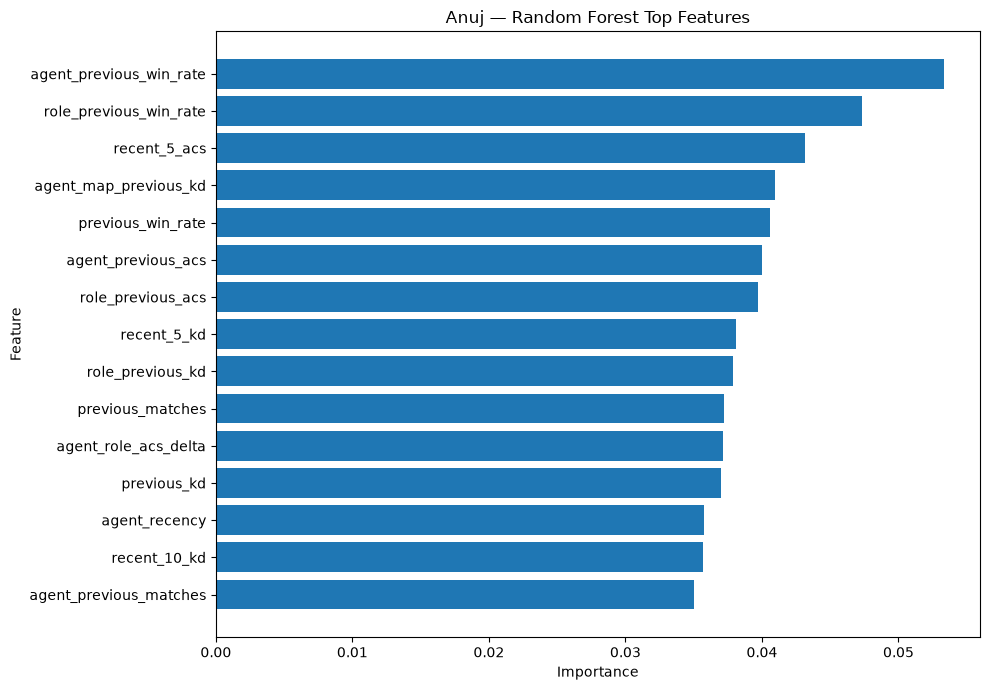

In [25]:

# ============================================================
# TOP FEATURE IMPORTANCE PLOT
# ============================================================

top_features = (
    feature_importance_df
    .head(15)
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    f"{PLAYER_NAME} — "
    f"{MODEL_NAME} Top Features"
)
plt.tight_layout()
plt.show()


# Recommendation Runtime Evaluation

The final role-aware recommendation layer returns up to **two personalized agents per role** for a selected map. Runtime is measured across every map represented in the player's history.

In [26]:

# ============================================================
# RECOMMENDATION RUNTIME EVALUATION
# ============================================================

runtime_records = []

available_maps = sorted(
    cleaned_df["Map"]
    .dropna()
    .unique()
)

for current_map in available_maps:

    start_time = perf_counter()

    recommendations = rank_agents_by_role(
        model_name=MODEL_NAME,
        model=final_model,
        history=cleaned_df,
        current_map=current_map,
        top_per_role=2
    )

    end_time = perf_counter()

    runtime_records.append(
        {
            "Map": current_map,
            "Recommendation Time (seconds)":
                end_time - start_time,
            "Agents Returned":
                len(recommendations)
        }
    )

runtime_results = pd.DataFrame(
    runtime_records
)

runtime_results


,Map,Recommendation Time (seconds),Agents Returned
0,Abyss,0.260279,8
1,Ascent,0.246202,8
2,Breeze,0.272202,8
3,Fracture,0.290468,8
4,Haven,0.260410,8
5,Lotus,0.238248,8
6,Pearl,0.244958,8
7,Split,0.284190,8
8,Summit,0.254488,8
9,Sunset,0.247543,8


In [27]:

average_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].mean()
)

maximum_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].max()
)

minimum_runtime = (
    runtime_results[
        "Recommendation Time (seconds)"
    ].min()
)

requirement_met = (
    maximum_runtime <= 20
)

print(f"Player: {PLAYER_NAME}")
print(f"Model: {MODEL_NAME}")
print(
    f"Average recommendation time: "
    f"{average_runtime:.4f} seconds"
)
print(
    f"Minimum recommendation time: "
    f"{minimum_runtime:.4f} seconds"
)
print(
    f"Maximum recommendation time: "
    f"{maximum_runtime:.4f} seconds"
)

print(
    "\nSystem Requirement "
    "(maximum 20 seconds):",
    "PASSED"
    if requirement_met
    else "NOT PASSED"
)


Player: Anuj
Model: Random Forest
Average recommendation time: 0.2599 seconds
Minimum recommendation time: 0.2382 seconds
Maximum recommendation time: 0.2905 seconds

System Requirement (maximum 20 seconds): PASSED


In [28]:

# ============================================================
# FINAL ROLE-AWARE RECOMMENDATION EXAMPLE
# ============================================================

CURRENT_MAP = "Haven"

final_recommendations = rank_agents_by_role(
    model_name=MODEL_NAME,
    model=final_model,
    history=cleaned_df,
    current_map=CURRENT_MAP,
    top_per_role=2
)

final_recommendations


,Role,Role Rank,Agent,Predicted Win Probability,role_usage_frequency,role_previous_matches,role_previous_win_rate,role_previous_acs,agent_previous_matches,agent_previous_win_rate,agent_previous_acs,agent_role_acs_delta,agent_familiarity
0,Sentinel,1,Veto,0.590768,0.600000,429,0.486936,185.904429,1,0.000000,122.000000,-63.904429,Very Low
1,Sentinel,2,Cypher,0.489398,0.600000,429,0.486936,185.904429,379,0.485175,187.474934,1.570505,High
2,Controller,1,Clove,0.544484,0.234965,168,0.479042,193.726190,6,0.333333,177.000000,-16.726190,Low
3,Controller,2,Omen,0.522931,0.234965,168,0.479042,193.726190,2,1.000000,118.500000,-75.226190,Very Low
4,Duelist,1,Phoenix,0.612844,0.102098,73,0.410959,182.150685,1,0.000000,143.000000,-39.150685,Very Low
5,Duelist,2,Raze,0.543052,0.102098,73,0.410959,182.150685,2,0.500000,169.000000,-13.150685,Very Low
6,Initiator,1,Sova,0.618359,0.062937,45,0.444444,181.888889,1,0.000000,114.000000,-67.888889,Very Low
7,Initiator,2,Gekko,0.560984,0.062937,45,0.444444,181.888889,3,0.666667,144.000000,-37.888889,Very Low


In [29]:

# ============================================================
# SAVE MODEL-SPECIFIC RESULTS
# ============================================================

tuning_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_hyperparameter_tuning.csv",
    index=False
)

validation_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_validation_results.csv",
    index=False
)

final_test_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_final_test_results.csv",
    index=False
)

feature_importance_df.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_feature_importance.csv",
    index=False
)

runtime_results.to_csv(
    RESULTS_DIR
    / f"{RESULT_PREFIX}_{MODEL_SLUG}_runtime_results.csv",
    index=False
)

final_recommendations.to_csv(
    RESULTS_DIR
    / (
        f"{RESULT_PREFIX}_{MODEL_SLUG}_"
        f"{CURRENT_MAP.lower()}_recommendations.csv"
    ),
    index=False
)

print("Saved result files for:", MODEL_NAME)


Saved result files for: Random Forest


# Final Interpretation

In [30]:

from IPython.display import display, Markdown

test_mrr = final_test_results.loc[0, "MRR"]
test_hit5 = final_test_results.loc[0, "Hit@5"]
test_hit6 = final_test_results.loc[0, "Hit@6"]

evaluated_matches = (
    final_test_results.loc[
        0,
        "Evaluated Matches"
    ]
)

top_feature_names = (
    feature_importance_df["Feature"]
    .head(5)
    .tolist()
)

top_feature_text = ", ".join(
    [
        f"**{feature}**"
        for feature in top_feature_names
    ]
)

runtime_status = (
    "satisfied"
    if requirement_met
    else "was not satisfied"
)

interpretation_text = f"""
# Final Model Interpretation

For **{PLAYER_NAME}**, this notebook trained and evaluated only the
**{MODEL_NAME}** algorithm.

Hyperparameters were selected using an internal chronological tuning period.
The external validation and held-out test periods were not used for
hyperparameter selection.

## Held-Out Test Performance

The model was evaluated on **{evaluated_matches} historical test matches**
that could be evaluated using the available candidate-agent history.

- **MRR:** {test_mrr:.4f}
- **Hit@5:** {test_hit5:.2%}
- **Hit@6:** {test_hit6:.2%}

Hit@5, Hit@6, and MRR evaluate the retrospective raw candidate ranking.
The final user-facing recommendation layer is role-aware and returns up to
**two agents per role**.

## Model Interpretation

The five most influential learned features were:

{top_feature_text}

Feature importance describes the behaviour of the trained model and should not
be interpreted as causal evidence.

## Runtime Performance

- **Average recommendation time:** {average_runtime:.4f} seconds
- **Maximum recommendation time:** {maximum_runtime:.4f} seconds

The project requirement of returning recommendations within approximately
**20 seconds** was therefore **{runtime_status}**.

Overall, this notebook demonstrates a complete, leakage-aware and
player-specific {MODEL_NAME} recommendation pipeline.
"""

display(
    Markdown(interpretation_text)
)



# Final Model Interpretation

For **Anuj**, this notebook trained and evaluated only the
**Random Forest** algorithm.

Hyperparameters were selected using an internal chronological tuning period.
The external validation and held-out test periods were not used for
hyperparameter selection.

## Held-Out Test Performance

The model was evaluated on **105 historical test matches**
that could be evaluated using the available candidate-agent history.

- **MRR:** 0.1004
- **Hit@5:** 9.52%
- **Hit@6:** 12.38%

Hit@5, Hit@6, and MRR evaluate the retrospective raw candidate ranking.
The final user-facing recommendation layer is role-aware and returns up to
**two agents per role**.

## Model Interpretation

The five most influential learned features were:

**agent_previous_win_rate**, **role_previous_win_rate**, **recent_5_acs**, **agent_map_previous_kd**, **previous_win_rate**

Feature importance describes the behaviour of the trained model and should not
be interpreted as causal evidence.

## Runtime Performance

- **Average recommendation time:** 0.2599 seconds
- **Maximum recommendation time:** 0.2905 seconds

The project requirement of returning recommendations within approximately
**20 seconds** was therefore **satisfied**.

Overall, this notebook demonstrates a complete, leakage-aware and
player-specific Random Forest recommendation pipeline.



# Conclusion

This notebook implements a complete **Random Forest** pipeline for the
role-aware VALORANT Personal Coach project.

The model is trained using chronological historical information from one
player's Competitive match history. Current-match performance statistics are
not used directly as pre-match predictors.

The workflow includes:

- chronological train/validation/test splitting,
- role-aware historical features,
- algorithm-specific preprocessing,
- hyperparameter optimization,
- retrospective ranking evaluation using MRR, Hit@5, and Hit@6,
- model interpretation,
- runtime measurement,
- and final role-aware recommendations with up to two agents per role.

The same notebook can later be reused for another player's standardized feature
dataset by changing only the dataset configuration cell at the top.
